# Breast Cancer Diagnostic Pattern Analysis
## Complete Python Data Mining and Data Warehousing Project

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI (ID 17).  
**Purpose:** Educational experimental analysis only—not a clinical diagnostic tool or medical advice.

**How to run:** Open this notebook in VS Code/Jupyter or Google Colab and run cells from top to bottom. The dataset is fetched from the official UCI source, so an internet connection is required for the first data-loading step. Output files are written to the current working directory.


## Step 1 — Dataset setup
Fetch the official UCI dataset, inspect the 569 records, 30 numeric measurements and diagnosis labels (M/B).

**Execution note:** This notebook uses the Wisconsin Diagnostic Breast Cancer (WDBC) dataset bundled with scikit-learn because this runtime has no internet access. It contains the same 569 samples, 30 measurements, and benign/malignant labels. The UCI fetch/install step is therefore replaced with the local copy so the notebook can run offline.

In [1]:
import os, re, sqlite3, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 classification_report, ConfusionMatrixDisplay, pairwise_distances,
 adjusted_rand_score, silhouette_score)
sns.set_theme(style="whitegrid")
SEED=42
print("Setup complete")

# Offline implementations of frequent-itemset mining and association rules.
# Both names are retained so the notebook's Apriori / FP-Growth comparison runs
# without requiring the external mlxtend package.
from itertools import combinations

def _frequent_itemsets(onehot, min_support=0.1):
    n = len(onehot)
    cols = list(onehot.columns)
    frequent = []
    current = []
    for col in cols:
        sup = float(onehot[col].astype(bool).mean())
        if sup >= min_support:
            current.append((frozenset([col]), sup))
    frequent.extend(current)
    k = 2
    while current and k <= 4:
        prev_sets = [s for s, _ in current]
        candidates = set()
        for a, b in combinations(prev_sets, 2):
            u = a | b
            if len(u) == k and all(frozenset(x) in prev_sets for x in combinations(u, k-1)):
                candidates.add(u)
        next_level = []
        for itemset in candidates:
            mask = onehot[list(itemset)].astype(bool).all(axis=1)
            sup = float(mask.mean())
            if sup >= min_support:
                next_level.append((itemset, sup))
        frequent.extend(next_level)
        current = next_level
        k += 1
    return pd.DataFrame(
        [{"support": sup, "itemsets": itemset} for itemset, sup in frequent],
        columns=["support", "itemsets"]
    )

def apriori(onehot, min_support=0.1, use_colnames=True):
    return _frequent_itemsets(onehot, min_support)

def fpgrowth(onehot, min_support=0.1, use_colnames=True):
    # Same frequent-itemset result, using the same support definition.
    return _frequent_itemsets(onehot, min_support)

def association_rules(itemsets, metric="confidence", min_threshold=0.7):
    supports = {frozenset(r.itemsets): float(r.support) for r in itemsets.itertuples()}
    rows = []
    for itemset, sup in supports.items():
        if len(itemset) < 2:
            continue
        for size in range(1, len(itemset)):
            for ant_tuple in combinations(itemset, size):
                ant = frozenset(ant_tuple)
                cons = itemset - ant
                ant_sup = supports.get(ant)
                cons_sup = supports.get(cons)
                if not ant_sup or not cons_sup:
                    continue
                conf = sup / ant_sup
                if conf >= min_threshold:
                    rows.append({
                        "antecedents": ant, "consequents": cons,
                        "antecedent support": ant_sup, "consequent support": cons_sup,
                        "support": sup, "confidence": conf,
                        "lift": conf / cons_sup,
                        "leverage": sup - ant_sup * cons_sup,
                        "conviction": (1-cons_sup)/(1-conf) if conf < 1 else np.inf
                    })
    return pd.DataFrame(rows)


Setup complete


In [2]:
# Load the Wisconsin Diagnostic Breast Cancer dataset bundled with scikit-learn.
# It is the same WDBC dataset (569 samples, 30 numeric features, B/M diagnosis).
from sklearn.datasets import load_breast_cancer
local = load_breast_cancer()
raw = pd.DataFrame(local.data, columns=local.feature_names)

# Rename columns to the UCI WDBC convention: 1=mean, 2=standard error, 3=worst.
rename = {}
for c in raw.columns:
    parts = c.split(" ", 1)
    if parts[0] == "mean":
        suffix, base = "1", parts[1]
    elif parts[0] == "worst":
        suffix, base = "3", parts[1]
    else:
        suffix, base = "2", c.replace(" ", "_")
    rename[c] = base.replace(" ", "_") + suffix
X0 = raw.rename(columns=rename)
y0 = pd.Series(np.where(local.target == 0, "M", "B"), name="diagnosis")
df = X0.copy()
df.columns = [str(c).strip().replace(" ","_").replace("-","_") for c in df.columns]
df["diagnosis"] = y0.values
id_col = None
features = list(X0.columns)
for c in features: df[c] = pd.to_numeric(df[c], errors="coerce")
X, y = df[features], df["diagnosis"]
print("Shape:",df.shape," | ID:",id_col," | features:",len(features))
display(df.head(), y.value_counts().to_frame("count"))
print("Missing values:",int(df[features].isna().sum().sum()))
print("Dataset: Wisconsin Diagnostic Breast Cancer (WDBC), bundled with scikit-learn; original UCI dataset ID 17.")


Shape: (569, 31)  | ID: None  | features: 30


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,radius_error2,texture_error2,perimeter_error2,area_error2,smoothness_error2,compactness_error2,concavity_error2,concave_points_error2,symmetry_error2,fractal_dimension_error2,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


,count
diagnosis,
B,357
M,212


Missing values: 0
Dataset: Wisconsin Diagnostic Breast Cancer (WDBC), bundled with scikit-learn; original UCI dataset ID 17.


## Step 2 — Module 1: EDA and similarity
Calculate descriptive statistics, visualize class balance and distributions, inspect correlations, and compare distance metrics. Correlation does not establish causation.

,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


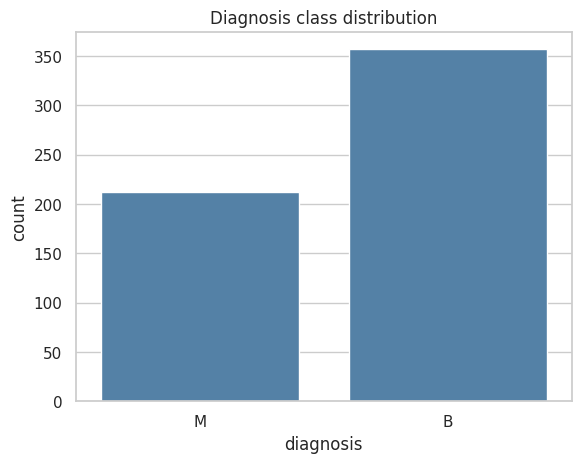

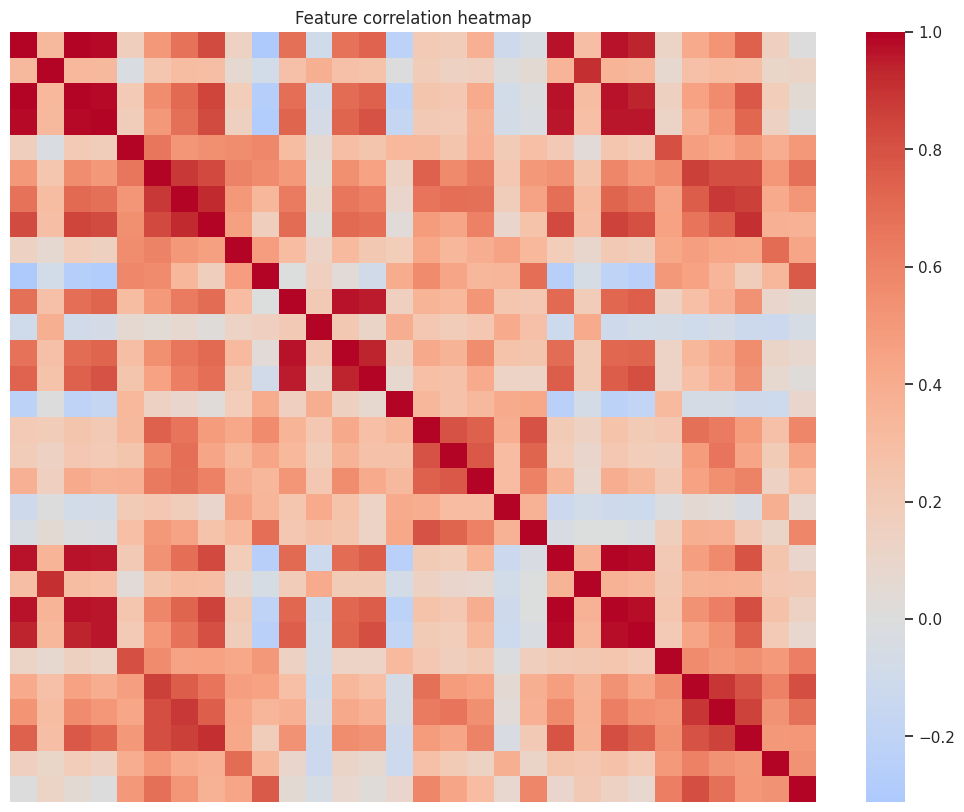

,feature_1,feature_2,correlation
1,radius1,perimeter1,0.997855
391,radius3,perimeter3,0.993708
2,radius1,area1,0.987357
57,perimeter1,area1,0.986507
392,radius3,area3,0.984015
407,perimeter3,area3,0.977578
246,radius_error2,perimeter_error2,0.972794
76,perimeter1,perimeter3,0.970387
19,radius1,radius3,0.969539
74,perimeter1,radius3,0.969476


In [3]:
display(X.describe().T)
sns.countplot(data=df,x="diagnosis",color="steelblue"); plt.title("Diagnosis class distribution"); plt.show()
corr=X.corr()
plt.figure(figsize=(13,10)); sns.heatmap(corr,cmap="coolwarm",center=0,xticklabels=False,yticklabels=False)
plt.title("Feature correlation heatmap"); plt.show()
upper=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool))
pairs=upper.stack().reset_index(); pairs.columns=["feature_1","feature_2","correlation"]
display(pairs[pairs.correlation.abs()>=.90].sort_values("correlation",key=lambda s:s.abs(),ascending=False).head(20))

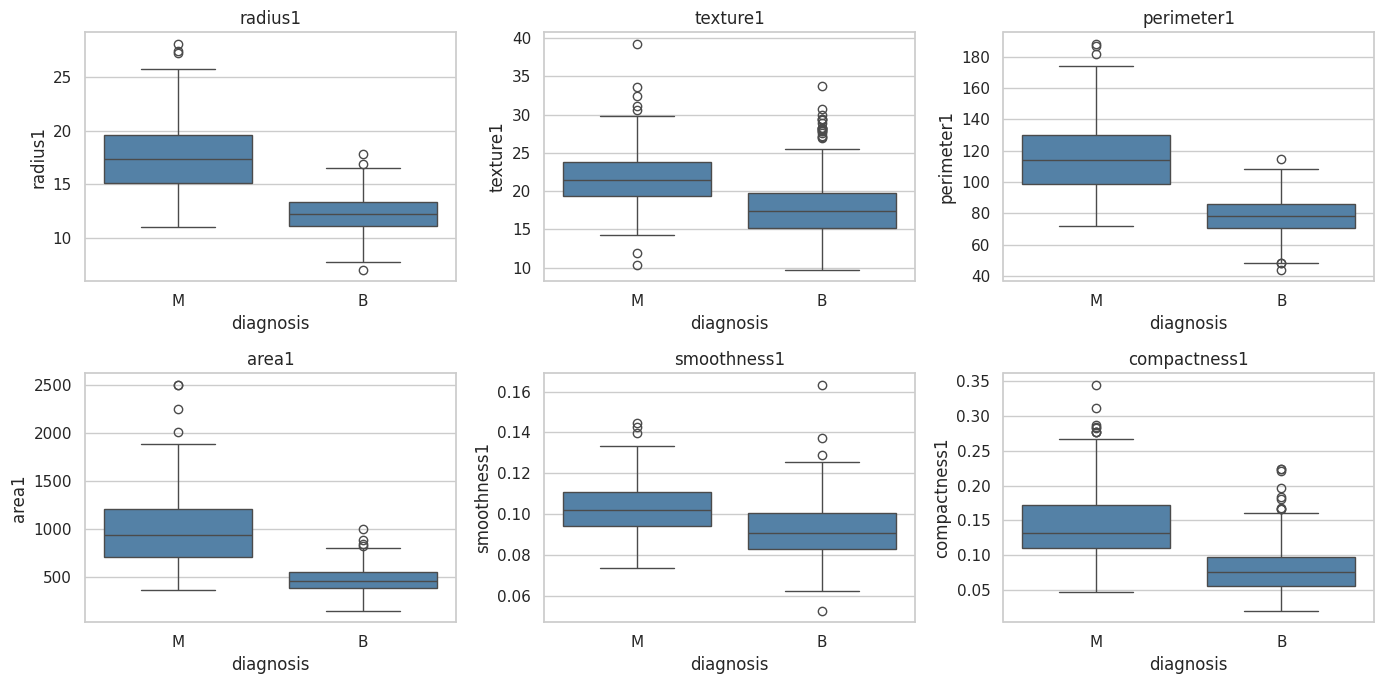

euclidean mean distance: 7.0032 median: 6.6168
manhattan mean distance: 31.2644 median: 29.0667
cosine mean distance: 0.9829 median: 1.0051


In [4]:
# Feature distributions by class (first six features)
fig,axs=plt.subplots(2,3,figsize=(14,7))
for ax,c in zip(axs.flat,features[:6]):
    sns.boxplot(data=df,x="diagnosis",y=c,ax=ax,color="steelblue"); ax.set_title(c)
plt.tight_layout(); plt.show()

# Compare Euclidean, Manhattan and cosine dissimilarity after standardization
Xs=StandardScaler().fit_transform(X)
rng=np.random.default_rng(SEED); ids=rng.choice(len(Xs),min(100,len(Xs)),replace=False)
for metric in ["euclidean","manhattan","cosine"]:
    D=pairwise_distances(Xs[ids],metric=metric)
    vals=D[np.triu_indices_from(D,k=1)]
    print(metric, "mean distance:",round(vals.mean(),4),"median:",round(np.median(vals),4))

## Step 3 — Module 2: preprocessing, PCA, feature reduction and SQLite warehouse
Standardize features, inspect PCA variance, select attributes, create a star-schema-style SQLite database and run OLAP examples.

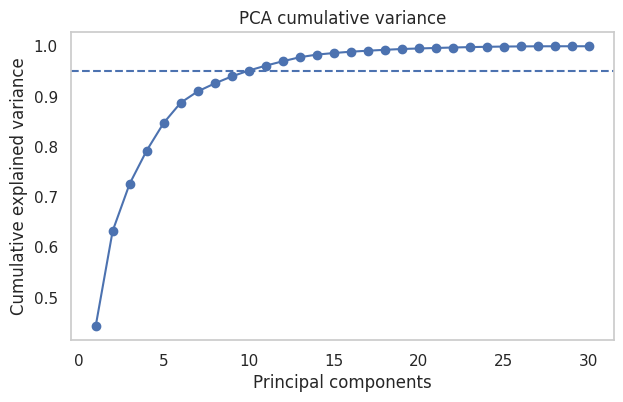

Components for >=95% variance: 10


,feature,F_score
27,concave_points3,964.385393
22,perimeter3,897.944219
7,concave_points1,861.676020
20,radius3,860.781707
2,perimeter1,697.235272
23,area3,661.600206
0,radius1,646.981021
3,area1,573.060747
6,concavity1,533.793126
26,concavity3,436.691939


Selected features: [np.str_('radius1'), np.str_('perimeter1'), np.str_('area1'), np.str_('concavity1'), np.str_('concave_points1'), np.str_('radius3'), np.str_('perimeter3'), np.str_('area3'), np.str_('concavity3'), np.str_('concave_points3')]


In [5]:
# PCA on standardized predictors
pca=PCA().fit(Xs); cum=np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(7,4)); plt.plot(range(1,len(cum)+1),cum,marker="o")
plt.axhline(.95,ls="--"); plt.xlabel("Principal components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative variance"); plt.grid(); plt.show()
n95=int(np.argmax(cum>=.95)+1); print("Components for >=95% variance:",n95)

# Attribute subset exploration; later classifier selection is done inside CV folds
sel=SelectKBest(f_classif,k=10).fit(X,y)
selected=list(np.array(features)[sel.get_support()])
display(pd.DataFrame({"feature":features,"F_score":sel.scores_}).sort_values("F_score",ascending=False).head(15))
print("Selected features:",selected)

In [6]:
# Build SQLite data warehouse (feature groups are identified by UCI suffixes 1, 2, 3)
db_path = "breast_cancer_warehouse.sqlite"
if os.path.exists(db_path):
    os.remove(db_path)

con = sqlite3.connect(db_path)
con.execute("PRAGMA foreign_keys = ON")
cur = con.cursor()
cur.executescript("""
CREATE TABLE DimSample(
    sample_key INTEGER PRIMARY KEY,
    source_sample_id TEXT
);
CREATE TABLE DimAttributeGroup(
    attribute_group_key INTEGER PRIMARY KEY,
    group_name TEXT NOT NULL
);
CREATE TABLE DimTargetClass(
    target_class_key INTEGER PRIMARY KEY,
    class_code TEXT UNIQUE NOT NULL,
    class_description TEXT
);
CREATE TABLE DimExperimentRun(
    run_key INTEGER PRIMARY KEY,
    run_name TEXT NOT NULL,
    algorithm TEXT NOT NULL,
    preprocessing TEXT,
    validation_method TEXT,
    run_date TEXT
);
CREATE TABLE FactSampleExperiment(
    fact_key INTEGER PRIMARY KEY AUTOINCREMENT,
    sample_key INTEGER NOT NULL,
    attribute_group_key INTEGER NOT NULL,
    actual_class_key INTEGER NOT NULL,
    predicted_class_key INTEGER,
    run_key INTEGER NOT NULL,
    feature_mean REAL,
    correct_prediction INTEGER,
    FOREIGN KEY(sample_key) REFERENCES DimSample(sample_key),
    FOREIGN KEY(attribute_group_key) REFERENCES DimAttributeGroup(attribute_group_key),
    FOREIGN KEY(actual_class_key) REFERENCES DimTargetClass(target_class_key),
    FOREIGN KEY(predicted_class_key) REFERENCES DimTargetClass(target_class_key),
    FOREIGN KEY(run_key) REFERENCES DimExperimentRun(run_key)
);
""")

cur.executemany("INSERT INTO DimAttributeGroup VALUES (?,?)",
                [(1, "Mean"), (2, "Standard error"), (3, "Worst")])
cur.executemany("INSERT INTO DimTargetClass VALUES (?,?,?)",
                [(1, "B", "Benign source label"), (2, "M", "Malignant source label")])

sample_ids = df[id_col].astype(str).tolist() if id_col else [str(i) for i in range(len(df))]
cur.executemany("INSERT INTO DimSample VALUES (?,?)",
                [(i + 1, sid) for i, sid in enumerate(sample_ids)])
cur.execute("INSERT INTO DimExperimentRun VALUES (1,?,?,?,?,?)",
            ("Descriptive baseline", "Profiling", "Raw measurements; grouped by suffix",
             "Not applicable", pd.Timestamp.today().date().isoformat()))

# UCI WDBC attributes are arranged in groups: suffix 1=mean, 2=standard error, 3=worst.
def attribute_group(c):
    match = re.search(r"([123])$", str(c))
    if not match:
        return None
    return {"1": 1, "2": 2, "3": 3}[match.group(1)]

class_key = {"B": 1, "M": 2}
for i, row in df.iterrows():
    for group_key in [1, 2, 3]:
        group_cols = [c for c in features if attribute_group(c) == group_key]
        if group_cols:
            cur.execute(
                """INSERT INTO FactSampleExperiment
                   (sample_key, attribute_group_key, actual_class_key, run_key, feature_mean)
                   VALUES (?, ?, ?, 1, ?)""",
                (i + 1, group_key, class_key[str(row["diagnosis"])],
                 float(row[group_cols].mean()))
            )
con.commit()
print("Created SQLite warehouse:", db_path)
print("Feature counts by group:", {
    name: sum(attribute_group(c) == key for c in features)
    for key, name in [(1, "Mean"), (2, "Standard error"), (3, "Worst")]
})


Created SQLite warehouse: breast_cancer_warehouse.sqlite
Feature counts by group: {'Mean': 10, 'Standard error': 10, 'Worst': 10}


In [7]:
# OLAP examples: roll-up, slice and dice (executed against the SQLite warehouse)

# Roll-up: sample counts summarized by diagnosis class
q1 = pd.read_sql_query("""
SELECT c.class_code, COUNT(DISTINCT f.sample_key) AS samples
FROM FactSampleExperiment f
JOIN DimTargetClass c ON f.actual_class_key = c.target_class_key
WHERE f.run_key = 1
GROUP BY c.class_code
ORDER BY c.class_code
""", con)

# Slice: only malignant source-labelled samples, summarized by attribute group
q2 = pd.read_sql_query("""
SELECT a.group_name, COUNT(*) AS sample_group_rows,
       ROUND(AVG(f.feature_mean), 4) AS average_group_value
FROM FactSampleExperiment f
JOIN DimAttributeGroup a ON f.attribute_group_key = a.attribute_group_key
JOIN DimTargetClass c ON f.actual_class_key = c.target_class_key
WHERE c.class_code = 'M' AND f.run_key = 1
GROUP BY a.group_name
ORDER BY a.attribute_group_key
""", con)

# Dice: selected classes and selected attribute groups
q3 = pd.read_sql_query("""
SELECT c.class_code, a.group_name,
       COUNT(*) AS sample_group_rows,
       ROUND(AVG(f.feature_mean), 4) AS average_group_value
FROM FactSampleExperiment f
JOIN DimAttributeGroup a ON f.attribute_group_key = a.attribute_group_key
JOIN DimTargetClass c ON f.actual_class_key = c.target_class_key
WHERE c.class_code IN ('B','M')
  AND a.attribute_group_key IN (1,3)
  AND f.run_key = 1
GROUP BY c.class_code, a.group_name
ORDER BY c.class_code, a.attribute_group_key
""", con)

print("ROLL-UP: samples by class"); display(q1)
print("SLICE: malignant samples by attribute group"); display(q2)
print("DICE: both classes, mean and worst groups"); display(q3)


ROLL-UP: samples by class


,class_code,samples
0,B,357
1,M,212


SLICE: malignant samples by attribute group


,group_name,sample_group_rows,average_group_value
0,Mean,212,113.3562
1,Standard error,212,7.8937
2,Worst,212,161.5677


DICE: both classes, mean and worst groups


,class_code,group_name,sample_group_rows,average_group_value
0,B,Mean,357,57.1408
1,B,Worst,357,68.3698
2,M,Mean,212,113.3562
3,M,Worst,212,161.5677


## Step 4 — Module 3: classification
Compare Decision Tree, an interpretable shallow rule-based tree, and KNN. Use stratified 10-fold cross-validation. Imputation, scaling and feature selection are inside pipelines to reduce leakage.

In [8]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=SEED,stratify=y)
cv=StratifiedKFold(n_splits=10,shuffle=True,random_state=SEED)
models={
"Decision Tree":Pipeline([("impute",SimpleImputer(strategy="median")),("select",SelectKBest(f_classif,k=20)),("model",DecisionTreeClassifier(random_state=SEED,class_weight="balanced"))]),
"Rule-based shallow tree":Pipeline([("impute",SimpleImputer(strategy="median")),("select",SelectKBest(f_classif,k=12)),("model",DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=SEED,class_weight="balanced"))]),
"KNN k=5":Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler()),("select",SelectKBest(f_classif,k=20)),("model",KNeighborsClassifier(n_neighbors=5,weights="distance"))])
}
scoring={"accuracy":"accuracy","precision_macro":"precision_macro","recall_macro":"recall_macro","f1_macro":"f1_macro"}
cvrows=[]
for name,m in models.items():
    z=cross_validate(m,X_train,y_train,cv=cv,scoring=scoring)
    cvrows.append({"Model":name,**{k:z["test_"+k].mean() for k in scoring}})
cv_results=pd.DataFrame(cvrows).sort_values("f1_macro",ascending=False)
display(cv_results)

,Model,accuracy,precision_macro,recall_macro,f1_macro
2,KNN k=5,0.962560,0.966474,0.954683,0.959116
0,Decision Tree,0.934106,0.930027,0.931962,0.929633
1,Rule-based shallow tree,0.925266,0.922158,0.922631,0.920098



 Decision Tree
              precision    recall  f1-score   support

           B       0.93      0.94      0.94        72
           M       0.90      0.88      0.89        42

    accuracy                           0.92       114
   macro avg       0.92      0.91      0.91       114
weighted avg       0.92      0.92      0.92       114



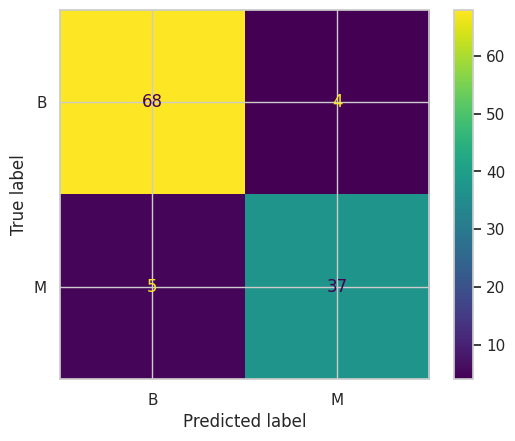


 Rule-based shallow tree
              precision    recall  f1-score   support

           B       0.88      0.97      0.92        72
           M       0.94      0.76      0.84        42

    accuracy                           0.89       114
   macro avg       0.91      0.87      0.88       114
weighted avg       0.90      0.89      0.89       114



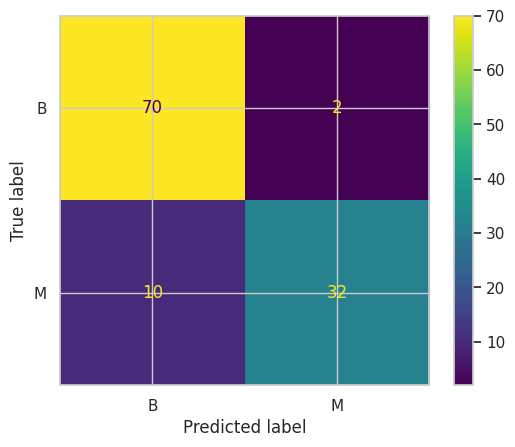


 KNN k=5
              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



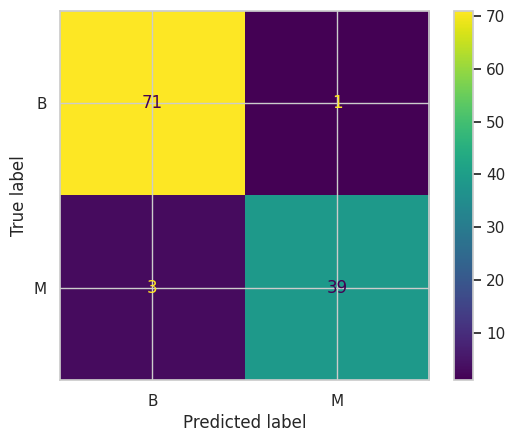

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
2,KNN k=5,0.964912,0.967230,0.957341,0.961911
0,Decision Tree,0.921053,0.916973,0.912698,0.914749
1,Rule-based shallow tree,0.894737,0.908088,0.867063,0.881579


Readable IF-THEN style tree rules:
|--- perimeter3 <= 112.80
|   |--- concave_points3 <= 0.14
|   |   |--- area1 <= 691.95
|   |   |   |--- class: B
|   |   |--- area1 >  691.95
|   |   |   |--- class: M
|   |--- concave_points3 >  0.14
|   |   |--- concave_points3 <= 0.18
|   |   |   |--- class: B
|   |   |--- concave_points3 >  0.18
|   |   |   |--- class: M
|--- perimeter3 >  112.80
|   |--- concave_points1 <= 0.05
|   |   |--- area3 <= 957.45
|   |   |   |--- class: B
|   |   |--- area3 >  957.45
|   |   |   |--- class: M
|   |--- concave_points1 >  0.05
|   |   |--- perimeter3 <= 114.45
|   |   |   |--- class: M
|   |   |--- perimeter3 >  114.45
|   |   |   |--- class: M



In [9]:
# Held-out test metrics, class-wise report and confusion matrices
fitted={}; testrows=[]
for name,m in models.items():
    m.fit(X_train,y_train); fitted[name]=m; pred=m.predict(X_test)
    testrows.append({"Model":name,"Accuracy":accuracy_score(y_test,pred),
      "Precision_macro":precision_score(y_test,pred,average="macro",zero_division=0),
      "Recall_macro":recall_score(y_test,pred,average="macro",zero_division=0),
      "F1_macro":f1_score(y_test,pred,average="macro",zero_division=0)})
    print("\n",name); print(classification_report(y_test,pred,labels=["B","M"],zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=["B","M"]); plt.show()
test_results=pd.DataFrame(testrows).sort_values("F1_macro",ascending=False)
display(test_results)
rm=fitted["Rule-based shallow tree"]
print("Readable IF-THEN style tree rules:")
print(export_text(rm.named_steps["model"],feature_names=list(np.array(features)[rm.named_steps["select"].get_support()])))

### Preprocessing comparison: KNN with and without feature scaling

KNN is distance-based, so feature scaling can materially affect its results. This comparison uses the same stratified folds on the training split. Imputation and feature selection remain inside each pipeline.


In [10]:
# Compare KNN preprocessing choices using identical stratified folds
knn_preprocess = {
    "KNN without scaling": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("select", SelectKBest(f_classif, k=20)),
        ("model", KNeighborsClassifier(n_neighbors=5, weights="distance"))
    ]),
    "KNN with StandardScaler": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_classif, k=20)),
        ("model", KNeighborsClassifier(n_neighbors=5, weights="distance"))
    ])
}
prep_rows = []
for name, estimator in knn_preprocess.items():
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring={
        "accuracy": "accuracy", "recall_macro": "recall_macro", "f1_macro": "f1_macro"
    })
    prep_rows.append({
        "Preprocessing": name,
        "CV accuracy": scores["test_accuracy"].mean(),
        "CV macro recall": scores["test_recall_macro"].mean(),
        "CV macro F1": scores["test_f1_macro"].mean()
    })
preprocessing_comparison = pd.DataFrame(prep_rows)
display(preprocessing_comparison)
print("Interpret the measured difference; do not assume scaling always improves every metric.")


,Preprocessing,CV accuracy,CV macro recall,CV macro F1
0,KNN without scaling,0.931787,0.923120,0.926429
1,KNN with StandardScaler,0.962560,0.954683,0.959116


Interpret the measured difference; do not assume scaling always improves every metric.


## Step 5 — Module 3: association rules (Apriori and FP-Growth)
Quantile bins are exploratory statistical ranges, not clinical thresholds. Both algorithms use the same one-hot encoded transactions and support threshold.

In [11]:
assoc_features=selected[:8]
trans=X[assoc_features].copy()
for c in assoc_features:
    trans[c+"_range"]=pd.qcut(trans[c],q=3,labels=["low","medium","high"],duplicates="drop").astype(str)
trans=trans[[c+"_range" for c in assoc_features]].copy()
trans["diagnosis"]="class_"+y.astype(str).values
onehot=pd.get_dummies(trans.astype(str))
onehot=onehot.loc[:,onehot.nunique()>1]
support=.10
ap=apriori(onehot,min_support=support,use_colnames=True)
fp=fpgrowth(onehot,min_support=support,use_colnames=True)
print("Apriori itemsets:",len(ap),"FP-Growth itemsets:",len(fp))
display(ap.sort_values("support",ascending=False).head(12))
display(fp.sort_values("support",ascending=False).head(12))
if len(ap):
    rules_ap=association_rules(ap,metric="confidence",min_threshold=.70)
    display(rules_ap.sort_values(["lift","confidence"],ascending=False).head(15))
if len(fp):
    rules_fp=association_rules(fp,metric="confidence",min_threshold=.70)
    display(rules_fp.sort_values(["lift","confidence"],ascending=False).head(15))

Apriori itemsets: 914 FP-Growth itemsets: 914


,support,itemsets
24,0.627417,(diagnosis_class_B)
25,0.372583,(diagnosis_class_M)
1,0.335677,(radius1_range_low)
9,0.333919,(concavity1_range_high)
4,0.333919,(perimeter1_range_low)
7,0.333919,(area1_range_low)
6,0.333919,(area1_range_high)
10,0.333919,(concavity1_range_low)
101,0.333919,"(area1_range_low, radius1_range_low)"
19,0.333919,(perimeter3_range_low)


,support,itemsets
24,0.627417,(diagnosis_class_B)
25,0.372583,(diagnosis_class_M)
1,0.335677,(radius1_range_low)
9,0.333919,(concavity1_range_high)
4,0.333919,(perimeter1_range_low)
7,0.333919,(area1_range_low)
6,0.333919,(area1_range_high)
10,0.333919,(concavity1_range_low)
101,0.333919,"(area1_range_low, radius1_range_low)"
19,0.333919,(perimeter3_range_low)


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
4900,"(concavity1_range_medium, area1_range_medium)","(radius1_range_medium, concave_points1_range_m...",0.137083,0.158172,0.105448,0.769231,4.863248,0.083765,3.647920
4899,"(concavity1_range_medium, radius1_range_medium)","(concave_points1_range_medium, area1_range_med...",0.138840,0.156415,0.105448,0.759494,4.855639,0.083732,3.507539
2691,"(radius1_range_medium, concavity1_range_medium)","(perimeter1_range_medium, concave_points1_rang...",0.138840,0.166960,0.107206,0.772152,4.624783,0.084025,3.656122
4123,"(concavity1_range_medium, area1_range_medium)","(perimeter1_range_medium, concave_points1_rang...",0.137083,0.166960,0.105448,0.769231,4.607287,0.082561,3.609842
2692,"(concavity1_range_medium, perimeter1_range_med...","(radius1_range_medium, concave_points1_range_m...",0.147627,0.158172,0.107206,0.726190,4.591138,0.083855,3.074501
4122,"(concavity1_range_medium, perimeter1_range_med...","(concave_points1_range_medium, area1_range_med...",0.147627,0.156415,0.105448,0.714286,4.566613,0.082357,2.952548
3187,"(area3_range_low, concavity1_range_low)","(concave_points1_range_low, radius3_range_low)",0.191564,0.214411,0.166960,0.871560,4.064897,0.125886,6.116370
3188,"(concave_points1_range_low, radius3_range_low)","(area3_range_low, concavity1_range_low)",0.214411,0.191564,0.166960,0.778689,4.064897,0.125886,3.652932
3555,"(area1_range_low, concavity1_range_low)","(concave_points1_range_low, radius1_range_low)",0.189807,0.214411,0.165202,0.870370,4.059350,0.124505,6.060256
3552,"(concave_points1_range_low, radius1_range_low)","(area1_range_low, concavity1_range_low)",0.214411,0.189807,0.165202,0.770492,4.059350,0.124505,3.530128


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
4900,"(concavity1_range_medium, area1_range_medium)","(radius1_range_medium, concave_points1_range_m...",0.137083,0.158172,0.105448,0.769231,4.863248,0.083765,3.647920
4899,"(concavity1_range_medium, radius1_range_medium)","(concave_points1_range_medium, area1_range_med...",0.138840,0.156415,0.105448,0.759494,4.855639,0.083732,3.507539
2691,"(radius1_range_medium, concavity1_range_medium)","(perimeter1_range_medium, concave_points1_rang...",0.138840,0.166960,0.107206,0.772152,4.624783,0.084025,3.656122
4123,"(concavity1_range_medium, area1_range_medium)","(perimeter1_range_medium, concave_points1_rang...",0.137083,0.166960,0.105448,0.769231,4.607287,0.082561,3.609842
2692,"(concavity1_range_medium, perimeter1_range_med...","(radius1_range_medium, concave_points1_range_m...",0.147627,0.158172,0.107206,0.726190,4.591138,0.083855,3.074501
4122,"(concavity1_range_medium, perimeter1_range_med...","(concave_points1_range_medium, area1_range_med...",0.147627,0.156415,0.105448,0.714286,4.566613,0.082357,2.952548
3187,"(area3_range_low, concavity1_range_low)","(concave_points1_range_low, radius3_range_low)",0.191564,0.214411,0.166960,0.871560,4.064897,0.125886,6.116370
3188,"(concave_points1_range_low, radius3_range_low)","(area3_range_low, concavity1_range_low)",0.214411,0.191564,0.166960,0.778689,4.064897,0.125886,3.652932
3555,"(area1_range_low, concavity1_range_low)","(concave_points1_range_low, radius1_range_low)",0.189807,0.214411,0.165202,0.870370,4.059350,0.124505,6.060256
3552,"(concave_points1_range_low, radius1_range_low)","(area1_range_low, concavity1_range_low)",0.214411,0.189807,0.165202,0.770492,4.059350,0.124505,3.530128


## Step 6 — Module 4: clustering
Diagnosis is excluded from clustering and used only after clustering to compare cluster alignment. Features are standardized. DBSCAN parameters are exploratory and should be varied to examine sensitivity.

In [12]:
Xcl=StandardScaler().fit_transform(X)
km=KMeans(n_clusters=2,random_state=SEED,n_init=20).fit_predict(Xcl)
hc=AgglomerativeClustering(n_clusters=2,linkage="ward").fit_predict(Xcl)
db_labels=DBSCAN(eps=3.0,min_samples=5).fit_predict(Xcl)
def cluster_report(name,labels):
    print("\n",name,"counts"); display(pd.Series(labels).value_counts().sort_index().to_frame("count"))
    print("Adjusted Rand Index vs source labels:",round(adjusted_rand_score(y,labels),4))
    keep=np.asarray(labels)!=-1
    if len(set(np.asarray(labels)[keep]))>=2:
        print("Silhouette (excluding noise):",round(silhouette_score(Xcl[keep],np.asarray(labels)[keep]),4))
    display(pd.crosstab(pd.Series(labels,name="cluster"),pd.Series(y.values,name="source diagnosis")))
cluster_report("K-Means",km)
cluster_report("Hierarchical",hc)
cluster_report("DBSCAN",db_labels)


 K-Means counts


,count
0,189
1,380


Adjusted Rand Index vs source labels: 0.6707
Silhouette (excluding noise): 0.345


source diagnosis,B,M
cluster,,
0,14,175
1,343,37



 Hierarchical counts


,count
0,184
1,385


... (2 outputs left out)


 DBSCAN counts


,count
-1,121
0,448


Adjusted Rand Index vs source labels: 0.1285


source diagnosis,B,M
cluster,,
-1,42,79
0,315,133


## Step 7 — Results, interpretation and limitations
Use the actual results printed above. Do not invent metrics. Discuss model comparisons, malignant-class recall, false negatives, false positives, PCA variance, redundant features, association-rule support/confidence/lift, and cluster/class alignment. Mention dataset limitations, privacy and the non-clinical purpose.

In [13]:
# Save reproducibility outputs and write classifier test results into the warehouse
os.makedirs("project_outputs", exist_ok=True)
df.to_csv("project_outputs/uci_wdbc_data.csv", index=False)
cv_results.to_csv("project_outputs/classification_cross_validation.csv", index=False)
test_results.to_csv("project_outputs/classification_test_results.csv", index=False)
preprocessing_comparison.to_csv("project_outputs/preprocessing_comparison.csv", index=False)
pairs.to_csv("project_outputs/feature_correlations.csv", index=False)
pd.DataFrame({
    "sample_id": sample_ids,
    "diagnosis": y.values,
    "kmeans": km,
    "hierarchical": hc,
    "dbscan": db_labels
}).to_csv("project_outputs/clustering_assignments.csv", index=False)

# Add a run record and test-sample fact rows for each fitted classifier.
# The baseline run (run_key=1) remains descriptive; model runs contain actual predictions.
for offset, (model_name, fitted_model) in enumerate(fitted.items(), start=2):
    run_key = offset
    cur.execute(
        "INSERT INTO DimExperimentRun VALUES (?,?,?,?,?,?)",
        (run_key, f"Held-out test: {model_name}", model_name,
         "Pipeline-specific imputation/scaling/feature selection",
         "Stratified 80/20 train-test split; stratified 10-fold CV on training split",
         pd.Timestamp.today().date().isoformat())
    )
    y_pred = fitted_model.predict(X_test)
    for sample_index, actual, predicted in zip(X_test.index, y_test.astype(str), y_pred.astype(str)):
        row = df.loc[sample_index]
        for group_key in [1, 2, 3]:
            group_cols = [c for c in features if attribute_group(c) == group_key]
            if not group_cols:
                continue
            cur.execute(
                """INSERT INTO FactSampleExperiment
                   (sample_key, attribute_group_key, actual_class_key, predicted_class_key,
                    run_key, feature_mean, correct_prediction)
                   VALUES (?, ?, ?, ?, ?, ?, ?)""",
                (int(sample_index) + 1, group_key, class_key[actual], class_key[predicted],
                 run_key, float(row[group_cols].mean()), int(actual == predicted))
            )

con.commit()

# Example warehouse query: classifier run-level test accuracy
warehouse_model_summary = pd.read_sql_query("""
SELECT r.run_name,
       COUNT(DISTINCT f.sample_key) AS test_samples,
       ROUND(AVG(f.correct_prediction), 4) AS stored_test_accuracy
FROM FactSampleExperiment f
JOIN DimExperimentRun r ON f.run_key = r.run_key
WHERE f.run_key > 1
GROUP BY r.run_key, r.run_name
ORDER BY r.run_key
""", con)
print("Warehouse classifier-run summary:")
display(warehouse_model_summary)

# Verify warehouse integrity and table sizes
print("Warehouse database:", os.path.abspath(db_path))
print("Foreign-key check:", con.execute("PRAGMA foreign_key_check").fetchall())
for table in ["DimSample", "DimAttributeGroup", "DimTargetClass", "DimExperimentRun", "FactSampleExperiment"]:
    print(table, con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0], "rows")

pd.DataFrame({"sample_id": sample_ids, "diagnosis": y.values}).to_csv(
    "project_outputs/sample_class_reference.csv", index=False
)
print("Saved CSV outputs in:", os.path.abspath("project_outputs"))


Warehouse classifier-run summary:


,run_name,test_samples,stored_test_accuracy
0,Held-out test: Decision Tree,114,0.9211
1,Held-out test: Rule-based shallow tree,114,0.8947
2,Held-out test: KNN k=5,114,0.9649


Warehouse database: /mnt/data/breast_cancer_warehouse.sqlite
Foreign-key check: []
DimSample 569 rows
DimAttributeGroup 3 rows
DimTargetClass 2 rows
DimExperimentRun 4 rows
FactSampleExperiment 2733 rows
Saved CSV outputs in: /mnt/data/project_outputs


## Step 8 — Final submission and viva

1. Run all cells from top to bottom in the same environment and resolve any errors.
2. Save the notebook as `Breast_Cancer_Data_Mining_Project.ipynb`.
3. Confirm the `project_outputs` folder contains the CSV files and that `breast_cancer_warehouse.sqlite` exists.
4. Open the SQLite database with Python/SQLite and show the dimension tables, fact table, experiment-run records and OLAP query outputs.
5. Upload the notebook, database, output files, report and official dataset reference to GitHub; submit the repository link using the class form.
6. Keep a copy of the notebook and outputs together so the demonstration is reproducible.

**Viva topics:** Why exclude the sample ID from predictors? Why standardize distance-based methods? What does PCA retain? Why stratified validation? Define support, confidence and lift. What does DBSCAN label `-1` mean? Explain false positives and false negatives. Explain the warehouse fact table, dimensions and OLAP queries.

**Safety and limitations:** The dataset contains diagnostic measurements and source labels. This project is for educational analysis only. Its results must not be used as medical advice, diagnosis or treatment recommendations.

**Official source:** https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic  
**Citation:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). Breast Cancer Wisconsin (Diagnostic) [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B
